<a href="https://colab.research.google.com/github/harshitadalne/AI-Practicals-Python-/blob/main/NNDL_Practical_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (2000, 20, 1)
Training data: (1600, 20, 1)
Testing data: (400, 20, 1)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 20, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 16)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 20, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 20, 16)         │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 20, 1)          │            17 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,281 (12.82 KB)

 Trainable params: 3,281 (12.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - loss: 0.4982 - val_loss: 0.4906
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.4808 - val_loss: 0.4701
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.4686 - val_loss: 0.4625
Epoch 4/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.4660 - val_loss: 0.4625
Epoch 5/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.4623 - val_loss: 0.4571
Epoch 6/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.4610 - val_loss: 0.4568
Epoch 7/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.4565 - val_loss: 0.4509
Epoch 8/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.4621 - val_loss: 0.4541
Epoch 9/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.4530 - val_loss: 0.4465
Epoch 10/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: 0.4468 - val_loss: 0.4398
Epoch 11/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.4400 - val_loss: 0.4294
Epoch 12/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.4

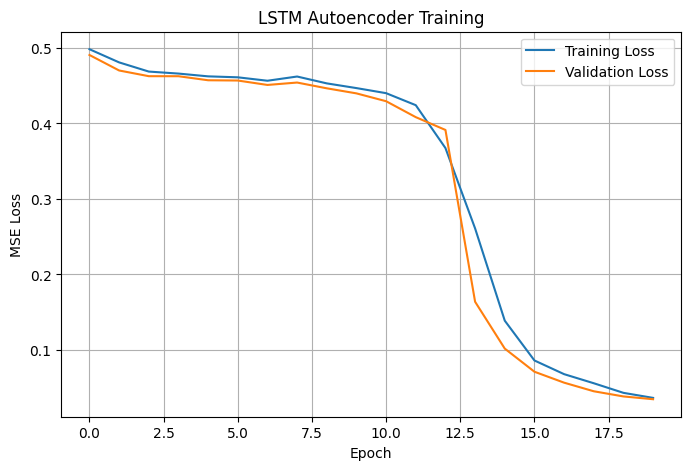

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step
Original shape: (400, 20, 1)
Reconstructed shape: (400, 20, 1)


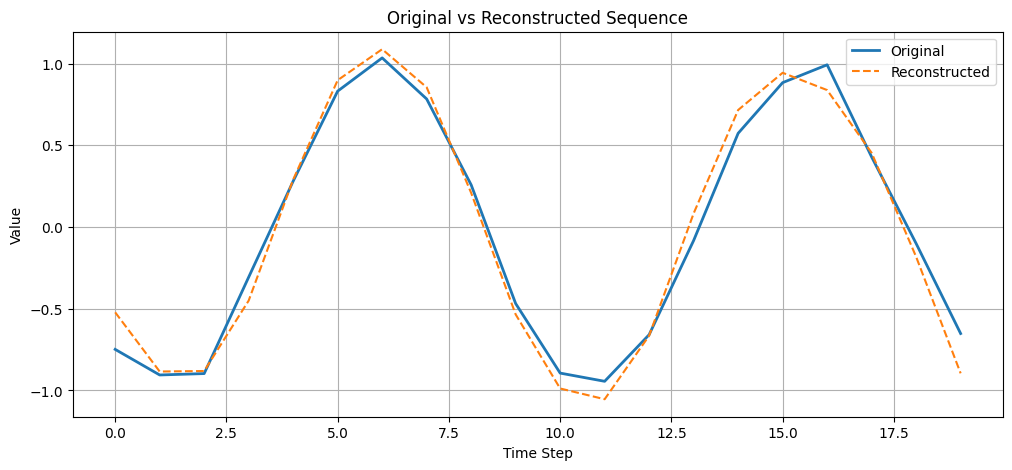

Mean reconstruction error: 0.033489798526114785
Maximum reconstruction error: 0.10143307770355417
Anomaly threshold: 0.0677816427800724
Number of anomalies: 20
Total test samples: 400


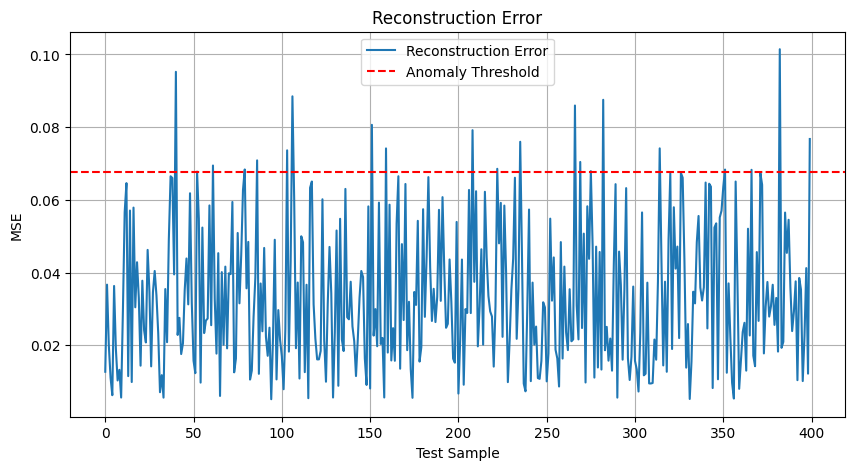

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, RepeatVector, TimeDistributed, Dense
from sklearn.model_selection import train_test_split

np.random.seed(42)
tf.random.set_seed(42)

n_samples = 2000
timesteps = 20
features = 1

X = []

for i in range(n_samples):
    phase = np.random.uniform(0, 2 * np.pi)
    x = np.linspace(0, 4 * np.pi, timesteps)
    sequence = np.sin(x + phase)
    sequence += np.random.normal(0, 0.05, timesteps)
    X.append(sequence)

X = np.array(X)
X = X.reshape(n_samples, timesteps, features)

print("Dataset shape:", X.shape)

X_train, X_test = train_test_split(
    X,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

latent_dim = 16

inputs = Input(shape=(timesteps, features))

encoded = LSTM(
    latent_dim,
    activation='tanh'
)(inputs)

decoded = RepeatVector(timesteps)(encoded)

decoded = LSTM(
    latent_dim,
    activation='tanh',
    return_sequences=True
)(decoded)

outputs = TimeDistributed(
    Dense(features)
)(decoded)

autoencoder = Model(inputs, outputs)

autoencoder.compile(
    optimizer='adam',
    loss='mse'
)

autoencoder.summary()

history = autoencoder.fit(
    X_train,
    X_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    shuffle=True
)

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('LSTM Autoencoder Training')
plt.legend()
plt.grid(True)
plt.show()

X_pred = autoencoder.predict(X_test)

print("Original shape:", X_test.shape)
print("Reconstructed shape:", X_pred.shape)

plt.figure(figsize=(12, 5))

plt.plot(
    X_test[0, :, 0],
    label='Original',
    linewidth=2
)

plt.plot(
    X_pred[0, :, 0],
    label='Reconstructed',
    linestyle='--'
)

plt.xlabel('Time Step')
plt.ylabel('Value')
plt.title('Original vs Reconstructed Sequence')
plt.legend()
plt.grid(True)
plt.show()

reconstruction_error = np.mean(
    np.square(X_test - X_pred),
    axis=(1, 2)
)

print(
    "Mean reconstruction error:",
    np.mean(reconstruction_error)
)

print(
    "Maximum reconstruction error:",
    np.max(reconstruction_error)
)

threshold = np.percentile(
    reconstruction_error,
    95
)

print("Anomaly threshold:", threshold)

anomalies = reconstruction_error > threshold

print("Number of anomalies:", np.sum(anomalies))
print("Total test samples:", len(X_test))

plt.figure(figsize=(10, 5))

plt.plot(
    reconstruction_error,
    label='Reconstruction Error'
)

plt.axhline(
    threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.xlabel('Test Sample')
plt.ylabel('MSE')
plt.title('Reconstruction Error')
plt.legend()
plt.grid(True)
plt.show()